In [1]:
from spatial_plots import combine_model_plots

In [1]:
from acs_plotting_maps import regions_dict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import xesmf as xe

In [5]:
directory = "/g/data/ia39/aus-ref-clim-data-nci/shapefiles/masks/AGCD-05i"
agcd = xr.open_dataset(
    f"{directory}/mask-fraction_agcd_v1-0-2_precip_weight_1960_2022.nc"
).fraction
ds = agcd.where(agcd >= 0.8)
res = 1
grid = xr.Dataset(
    {
        "lat": (
            ["lat"],
            np.arange(-44, -9.5 + res, res),
            {"units": "degrees_north"},
        ),
        "lon": (["lon"], np.arange(112, 154 + res, res), {"units": "degrees_east"}),
    }
)
regridder = xe.Regridder(ds, grid, "conservative_normed")
ds = regridder(agcd)
ds

/g/data/xv83/as3189/conda/envs/unseen/lib/python3.11/site-packages/xesmf/frontend.py:95: UserWarning: Variables {'lon_bnds'} not found in object but are referred to in the CF attributes.
  lon_bnds = ds.cf.get_bounds('longitude')


<xarray.DataArray (lat: 36, lon: 43)> Size: 12kB
array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.21715743, 0.21745608,
        0.17632817],
       [0.        , 0.        , 0.        , ..., 0.21866814, 0.21612765,
        0.14682574],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])
Coordinates:
  * lat      (lat) float64 288B -44.0 -43.0 -42.0 -41.0 ... -11.0 -10.0 -9.0
  * lon      (lon) int64 344B 112 113 114 115 116 117 ... 150 151 152 153 154
Attributes:
    regrid_method:  conservative_normed

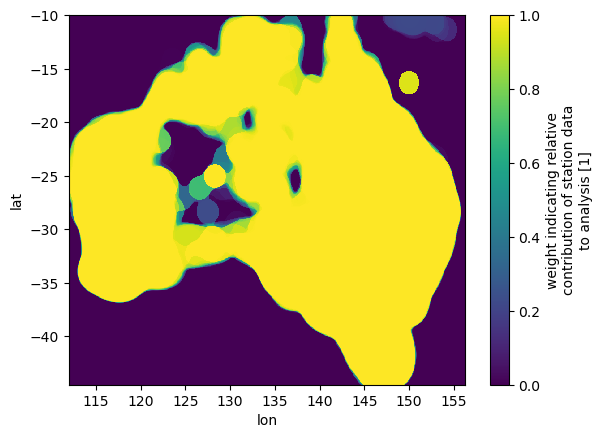

In [7]:
agcd.plot()

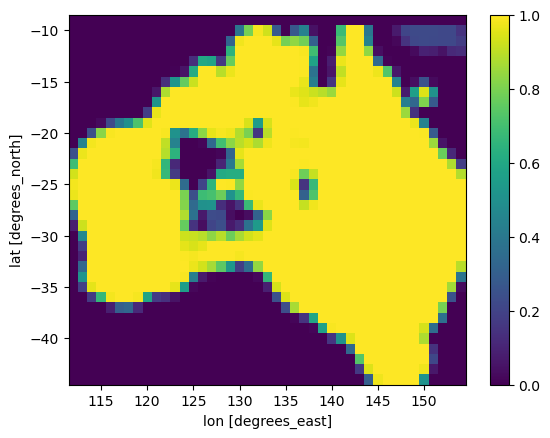

In [6]:
ds.plot()

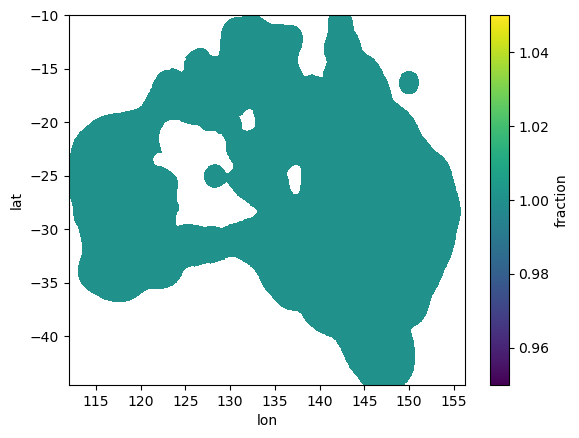

In [18]:
mask = agcd < 0.8

mask = xr.where(agcd < 0.8, np.nan, 1)
mask.plot()

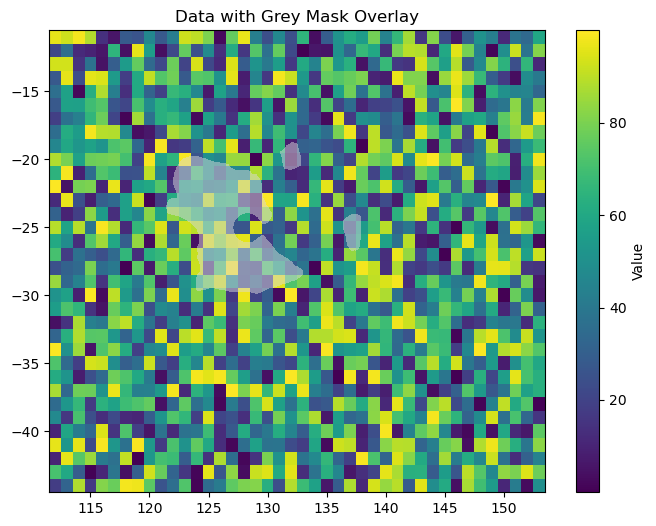

In [26]:
# Example data
lon = np.arange(112, 154, 1)
lat = np.arange(-44, -10, 1)
X, Y = np.meshgrid(lon, lat)
data = np.random.uniform(0, 100, size=(len(lat), len(lon)))

# Example: region to be grey
mask = xr.where(agcd < 0.8, 1, np.nan)
mask = mask.sel(lat=slice(-32, -18), lon=slice(121, 140))
# All non-NaN points set to 1 (won't be shown)

fig, ax = plt.subplots(figsize=(8, 6))
# Plot main data
pcm = ax.pcolormesh(X, Y, data, cmap="viridis")
plt.colorbar(pcm, ax=ax, label="Value")
# Overlay grey where mask is NaN
cmap_bad = "Greys"
grey_mask = np.isnan(mask)
ax.contourf(
    mask.lon,
    mask.lat,
    mask,
    cmap=cmap_bad,
    # vmin=0,
    # vmax=1,
    alpha=0.5,
)

ax.set_title("Data with Grey Mask Overlay")
plt.show()

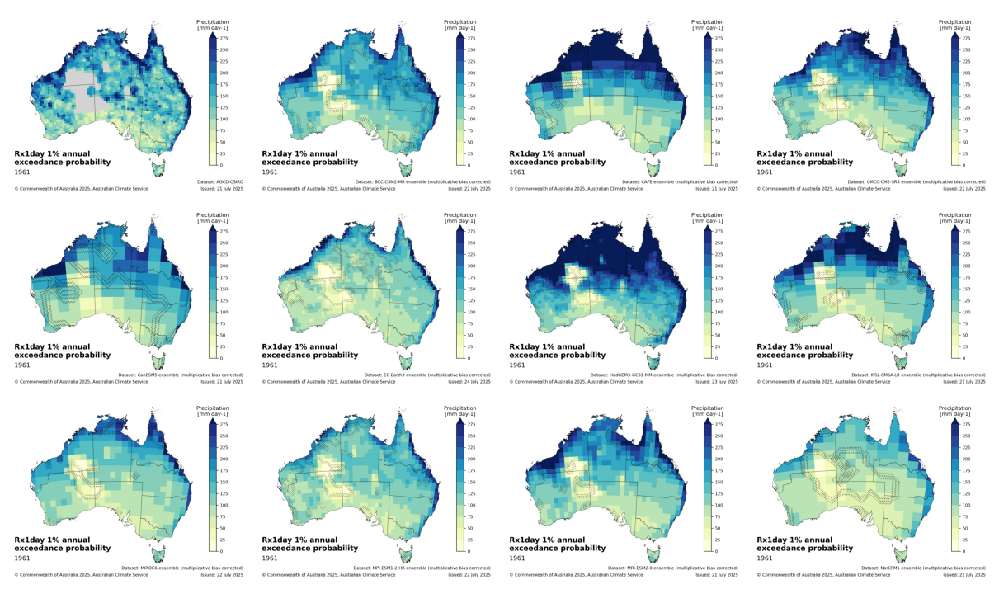

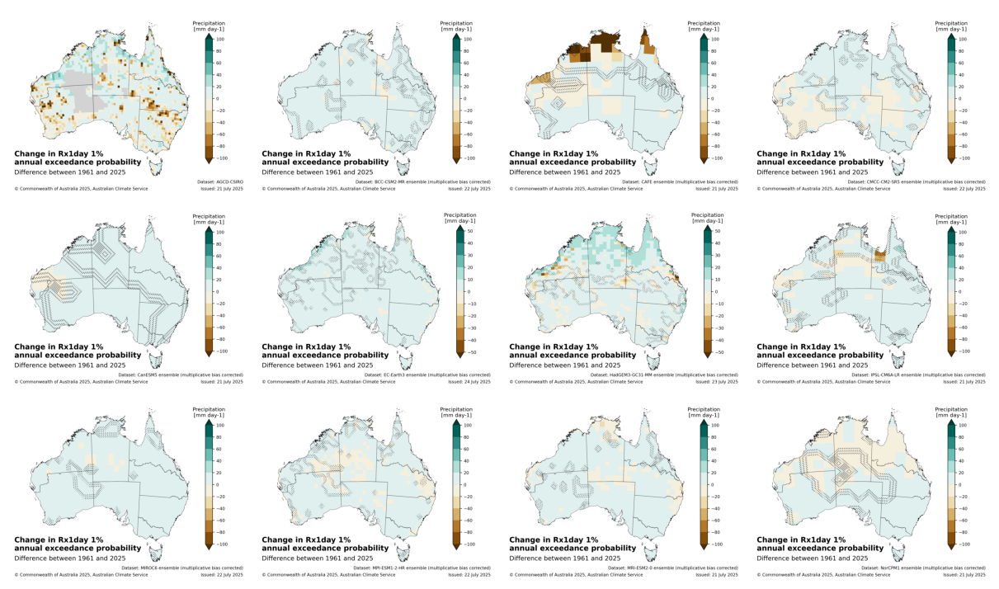

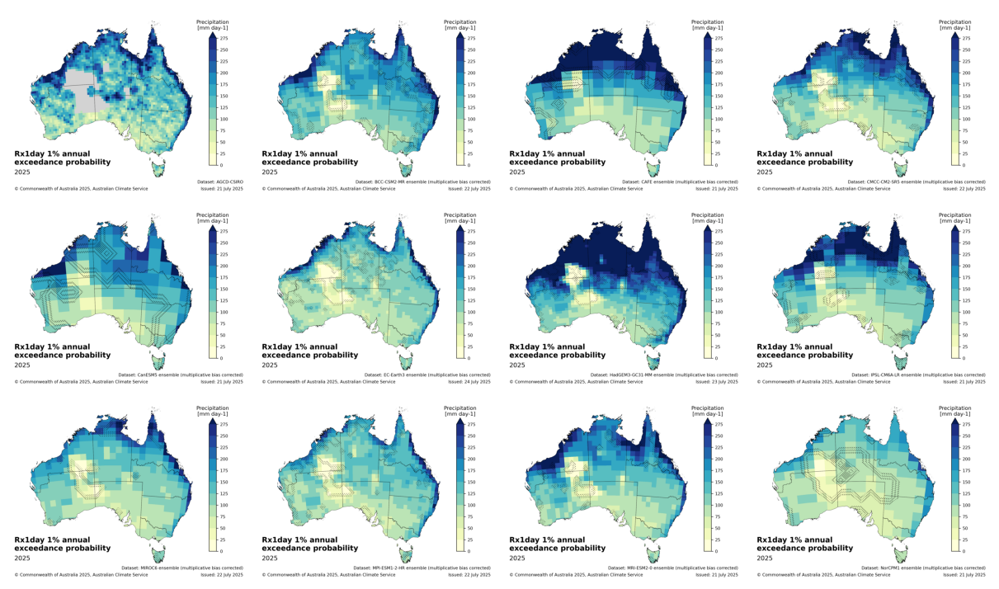

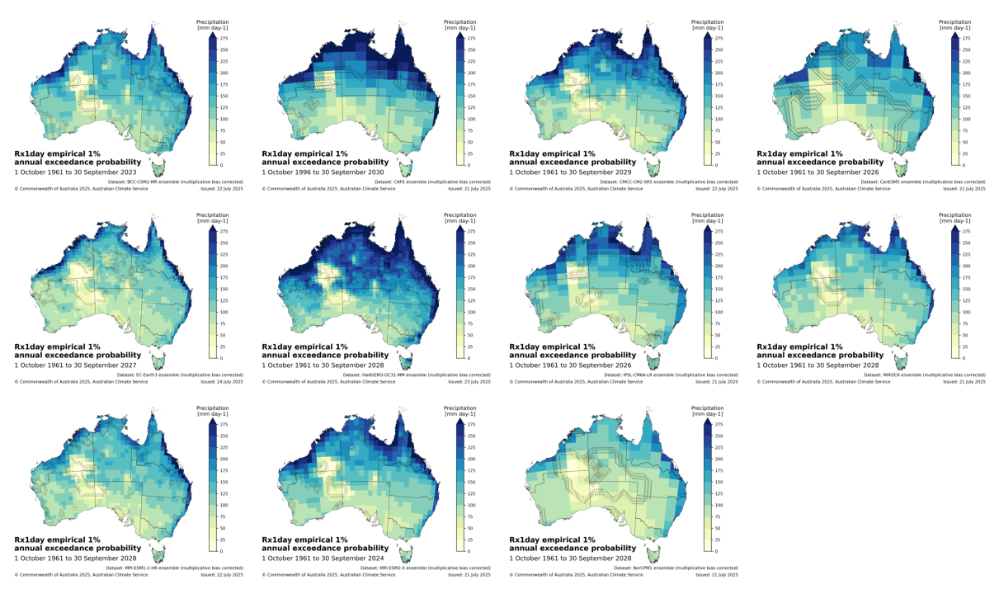

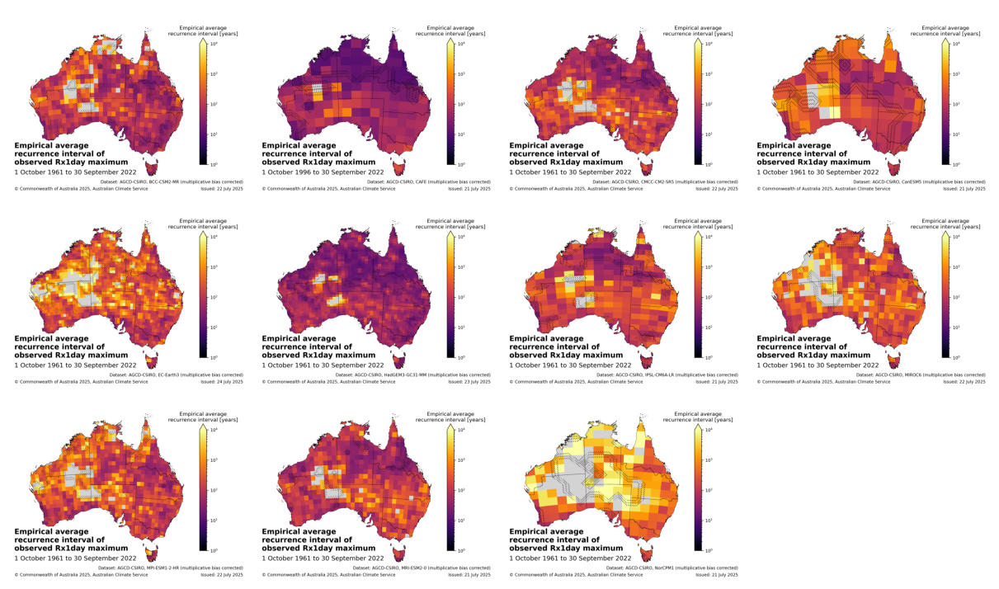

...

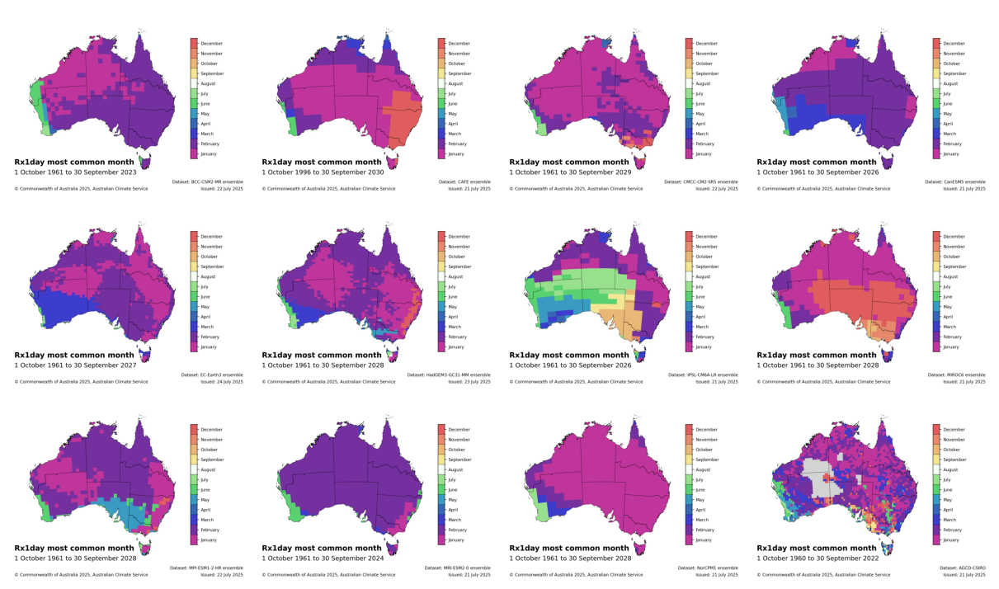

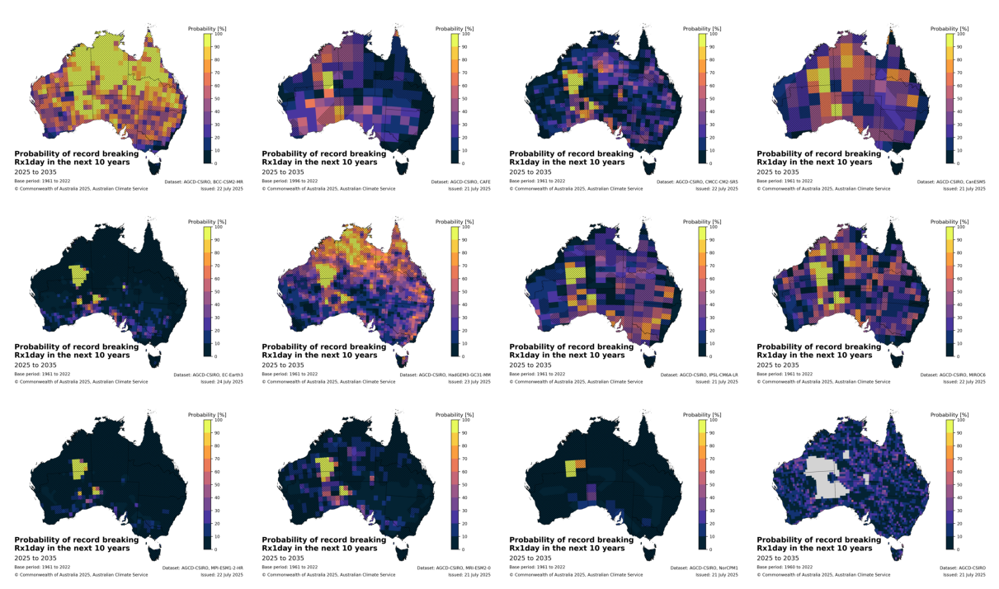

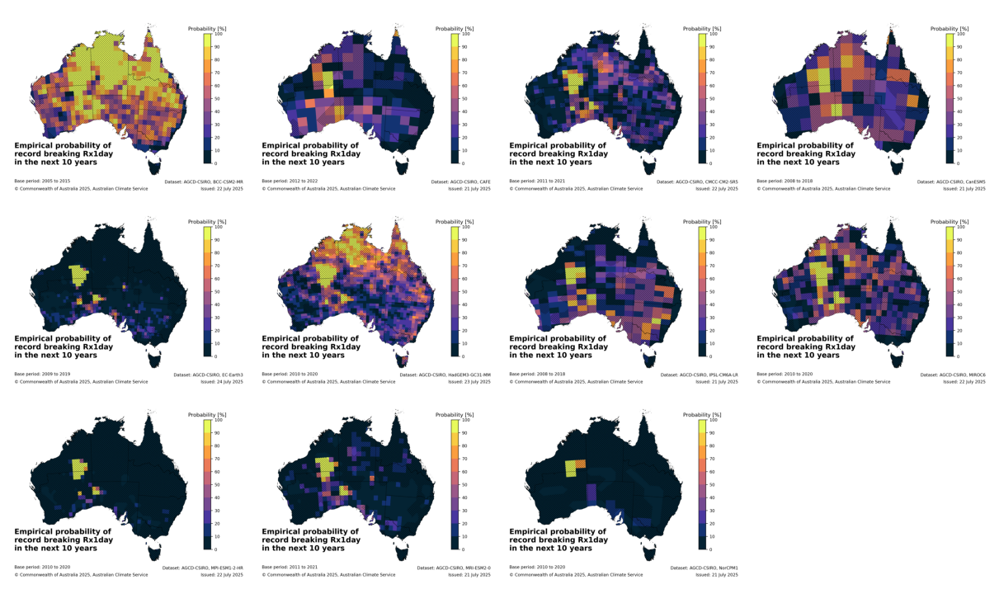

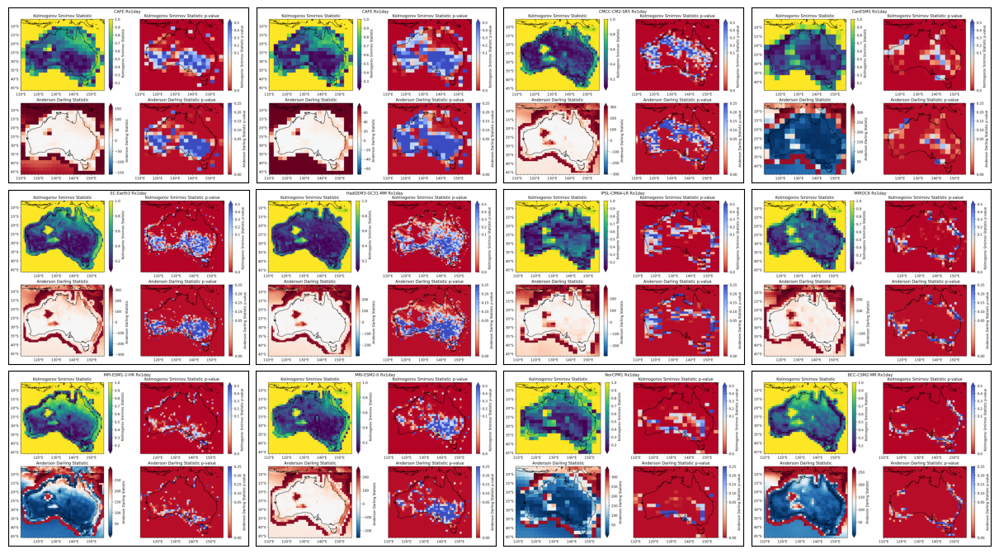

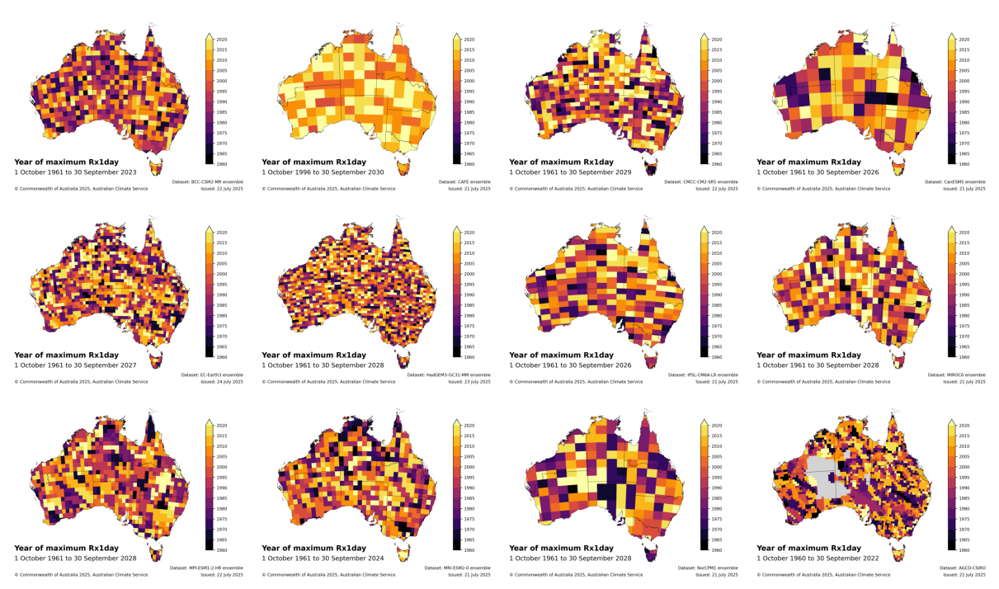

In [2]:
    metric = "rx1day"
    for bc in ["multiplicative", None]:
        combine_model_plots(
            metric=metric,
            bc=bc,
            obs_name="AGCD",
            fig_dir=f"/g/data/xv83/unseen-projects/outputs/{metric}/figures/",
            n_models=12,
        )